<a href="https://colab.research.google.com/github/diloo11/MachineLearning/blob/main/JS09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

LAB 1 ANNOY

In [4]:
# Install ANNOY
!pip install annoy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 5.1 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for annoy: filename=annoy-1.17.3-cp313-cp313-linux_x86_64.whl size=520039 sha256=4a0737af38bc90225434ec7e5acd9cd5200408f2577f28bbf3c9535d84bdcc72
  Stored in directory: /root/.cache/pip/wheels/fc/4e/87/f1f957e7382aa370452cff98276f51686924d5415e449800ed
Successfully built annoy


In [5]:
# Import Library
import numpy as np
import matplotlib.pyplot as plt
import time

from annoy import AnnoyIndex

In [6]:
# Build Random Dataset and Query Point
np.random.seed(42)
n_points = 1000
X = np.random.rand(n_points, 2) * 100  # random values in a 100x100 space

# Query point (pick 1 random data point)
query = X[np.random.randint(0, n_points)]

In [8]:
# Compute Exact NN Using Brute Force
# It will visit the data one by one
start = time.time()
distances = np.linalg.norm(X - query, axis=1)
idx_exact = np.argsort(distances)[:3]  # take the 3 nearest
time_exact = time.time() - start

print("Exact NN index:", idx_exact)
print("Exact NN distances:", distances[idx_exact])
print("Exact Time:", round(time_exact*1000, 4), "ms")

Exact NN index: [219 898 593]
Exact NN distances: [0.         1.36915938 2.27931544]
Exact Time: 8.8751 ms


In [9]:
# ANNOY 3 Trees
f = 2  # dimensions
t = AnnoyIndex(f, 'euclidean')
for i, vec in enumerate(X):
    t.add_item(i, vec)

t.build(3)  # 3 trees

start = time.time()
idx_ann = t.get_nns_by_vector(query, 3)  # find 3 NN
time_ann = time.time() - start

print("\nAnnoy NN index:", idx_ann)
print("Annoy NN distances:", [np.linalg.norm(X[i]-query) for i in idx_ann])
print("Annoy Time:", round(time_ann*1000, 4), "ms")


Annoy NN index: [219, 898, 770]
Annoy NN distances: [np.float64(0.0), np.float64(1.369159376273702), np.float64(2.568167959732514)]
Annoy Time: 0.1595 ms


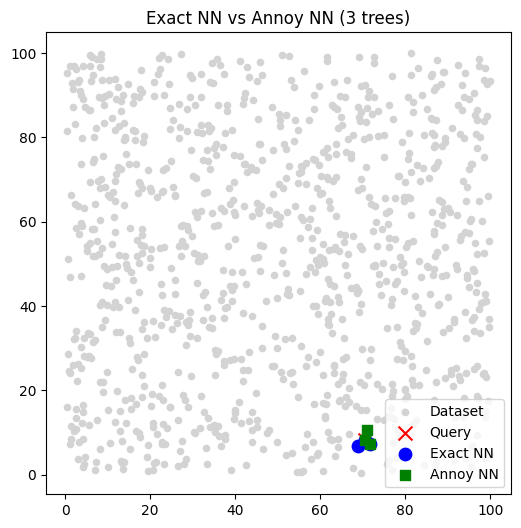

In [10]:
# Visualize
# Knowing the NN produced by Exact NN and ANNOY
plt.figure(figsize=(6,6))
plt.scatter(X[:,0], X[:,1], c="lightgray", s=20, label="Dataset")
plt.scatter(query[0], query[1], c="red", marker="x", s=100, label="Query")

# Exact NN marked in blue
plt.scatter(X[idx_exact,0], X[idx_exact,1], c="blue", s=80, label="Exact NN")

# Annoy NN marked in green
plt.scatter(X[idx_ann,0], X[idx_ann,1], c="green", s=50, marker="s", label="Annoy NN")

plt.legend()
plt.title("Exact NN vs Annoy NN (3 trees)")
plt.show()

LAB 2 FAISS

In [12]:
!pip install faiss-cpu
!pip install faiss-gpu

  Using cached faiss_gpu-1.16.0-cp310-abi3-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (8.1 kB)
  Using cached nvidia_cublas_cu12-12.9.3.13-py3-none-manylinux_2_27_x86_64.whl.metadata (1.8 kB)
Using cached faiss_gpu-1.16.0-cp310-abi3-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (137.0 MB)
Using cached nvidia_cublas_cu12-12.9.3.13-py3-none-manylinux_2_27_x86_64.whl (581.2 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [faiss-gpu]


In [13]:
import numpy as np
import faiss
import matplotlib.pyplot as plt
import time

In [ ]:
# Build random data
np.random.seed(42)
X = np.random.rand(1000, 2).astype('float32')  # 1000 data points in 2D
query = np.array([[0.5, 0.5]], dtype='float32')  # query point

In [ ]:
# Search NN using Exact NN
index_flat = faiss.IndexFlatL2(2)   # L2 = Euclidean distance
index_flat.add(X)

# Compute Exact NN Time
start = time.time()
D_flat, I_flat = index_flat.search(query, 3)  # Find 3 nearest neighbors
end = time.time()
time_flat = end - start

In [ ]:
# Compute FAISS
nlist = 10   # number of clusters (inverted lists)
m = 2        # number of subvectors
quantizer = faiss.IndexFlatL2(2)   # used by IVF for initial clustering
index_ivfpq = faiss.IndexIVFPQ(quantizer, 2, nlist, m, 8)  # 8 bits per subvector

index_ivfpq.train(X)  # train centroids
index_ivfpq.add(X)

start = time.time()
D_ivfpq, I_ivfpq = index_ivfpq.search(query, 3)
end = time.time()
time_ivfpq = end - start

In [ ]:
# Print the performances
print("Exact NN (Flat) indices:", I_flat, "distances:", D_flat)
print("IVF+PQ indices:", I_ivfpq, "distances:", D_ivfpq)
print("Exact Time:", time_flat)
print("IVF+PQ Time:", time_ivfpq)

Exact NN (Flat) indices: [[137 170 750]] distances: [[0.00013095 0.00077404 0.00079751]]
IVF+PQ indices: [[137 170 750]] distances: [[0.00012945 0.00079226 0.00080067]]
Exact Time: 0.0003230571746826172
IVF+PQ Time: 0.0002562999725341797


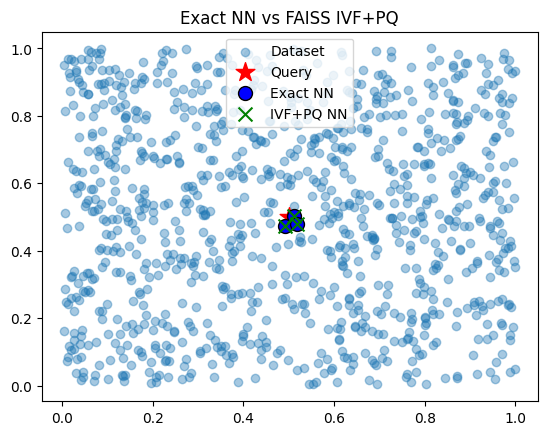

In [ ]:
# Visualize
plt.scatter(X[:,0], X[:,1], alpha=0.4, label="Dataset")
plt.scatter(query[:,0], query[:,1], c='red', marker='*', s=200, label="Query")

# Flat NN -> Exact NN
plt.scatter(X[I_flat[0],0], X[I_flat[0],1], c='blue', s=100, edgecolor='k', label="Exact NN")

# IVF+PQ NN -> FAISS
plt.scatter(X[I_ivfpq[0],0], X[I_ivfpq[0],1], c='green', marker='x', s=100, label="IVF+PQ NN")

plt.legend()
plt.title("Exact NN vs FAISS IVF+PQ")
plt.show()

LAB 3 HNSW

In [16]:
!pip install hnswlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for hnswlib: filename=hnswlib-0.8.0-cp313-cp313-linux_x86_64.whl size=2679796 sha256=5ebce08d1cf7c11d7cac64290136f5bd75e26a329fea64811fb22738c1083054
  Stored in directory: /root/.cache/pip/wheels/35/04/88/b31765a4b9957705e18065db4657e61fc8da54f50e3ef0b67e
Successfully built hnswlib


In [17]:
import hnswlib
import numpy as np
import time
from sklearn.neighbors import NearestNeighbors

In [ ]:
# Build Dummy Dataset
num_elements = 1000
dim = 2
data = np.random.random((num_elements, dim)).astype(np.float32)

# Query point
query = np.array([[0.5, 0.5]], dtype=np.float32)
k = 5  # search for 5 nearest neighbors

In [ ]:
# Build NN Model
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(data)

# Compute time performance
start = time.time()
distances, indices = nn.kneighbors(query)
end = time.time()

print("=== Exact NN ===")
print("Indices:", indices)
print("Distances:", distances)
print("Time:", end - start, "s")

=== Exact NN ===
Indices: [[830 247 473 913 592]]
Distances: [[0.00993625 0.01363944 0.01646171 0.03779694 0.03859071]]
Time: 0.07546043395996094 s


In [ ]:
# Initiate Index
p = hnswlib.Index(space='l2', dim=dim)

# Define Max Elements
p.init_index(max_elements=num_elements, ef_construction=100, M=16)

# Add Data
p.add_items(data)

# Set searching parameter
p.set_ef(50)   # tradeoff speed vs accuracy

start = time.time()
labels, distances = p.knn_query(query, k=k)
end = time.time()

print("\n=== HNSW ===")
print("Indices:", labels)
print("Distances:", distances)
print("Time:", end - start, "s")


=== HNSW ===
Indices: [[830 247 473 913 592]]
Distances: [[9.8728990e-05 1.8603441e-04 2.7098786e-04 1.4286089e-03 1.4892431e-03]]
Time: 0.0003142356872558594 s


LAB 4 COMPARISON ANNOY vs FAISS vs HNSW

In [ ]:
import numpy as np
import time
from annoy import AnnoyIndex
import faiss
import hnswlib

# ===============================
# Build 1 million rows with 5 dimensions
# ===============================
n_data = 1_000_000   # use 100_000 if memory is constrained
dim = 5
X = np.random.random((n_data, dim)).astype(np.float32)

# Query point
query = np.random.random((1, dim)).astype(np.float32)
k = 10

# ===============================
# 2. Annoy
# ===============================
print("=== Annoy ===")
ann_index = AnnoyIndex(dim, 'euclidean')

start = time.time()
for i in range(n_data):
    ann_index.add_item(i, X[i])
ann_index.build(10)  # 10 trees
build_time = time.time() - start

start = time.time()
neighbors = ann_index.get_nns_by_vector(query[0], k, include_distances=True)
query_time = time.time() - start

print("Build time:", build_time, "seconds")
print("Query time:", query_time, "seconds")
print("Neighbors:", neighbors[0][:5], "...")

# ===============================
# 3. FAISS (Flat Index)
# ===============================
print("\n=== FAISS (IndexFlatL2) ===")
faiss_index = faiss.IndexFlatL2(dim)

start = time.time()
faiss_index.add(X)
build_time = time.time() - start

start = time.time()
distances, indices = faiss_index.search(query, k)
query_time = time.time() - start

print("Build time:", build_time, "seconds")
print("Query time:", query_time, "seconds")
print("Neighbors:", indices[0][:5], "...")

# ===============================
# 4. HNSW (hnswlib)
# ===============================
print("\n=== HNSW (hnswlib) ===")
hnsw_index = hnswlib.Index(space='l2', dim=dim)

start = time.time()
hnsw_index.init_index(max_elements=n_data, ef_construction=200, M=16)
hnsw_index.add_items(X)
build_time = time.time() - start

hnsw_index.set_ef(50)

start = time.time()
labels, distances = hnsw_index.knn_query(query, k=k)
query_time = time.time() - start

print("Build time:", build_time, "seconds")
print("Query time:", query_time, "seconds")
print("Neighbors:", labels[0][:5], "...")

=== Annoy ===
Build time: 29.63311243057251 seconds
Query time: 0.00029087066650390625 seconds
Neighbors: [129179, 559276, 630783, 213191, 559393] ...

=== FAISS (IndexFlatL2) ===
Build time: 0.016177892684936523 seconds
Query time: 0.01072835922241211 seconds
Neighbors: [129179 559276 630783 213191 559393] ...

=== HNSW (hnswlib) ===
Build time: 201.4399528503418 seconds
Query time: 0.0005784034729003906 seconds
Neighbors: [129179 559276 630783 213191 559393] ...


LAB 5 Testing ANN Performance with Query Recall

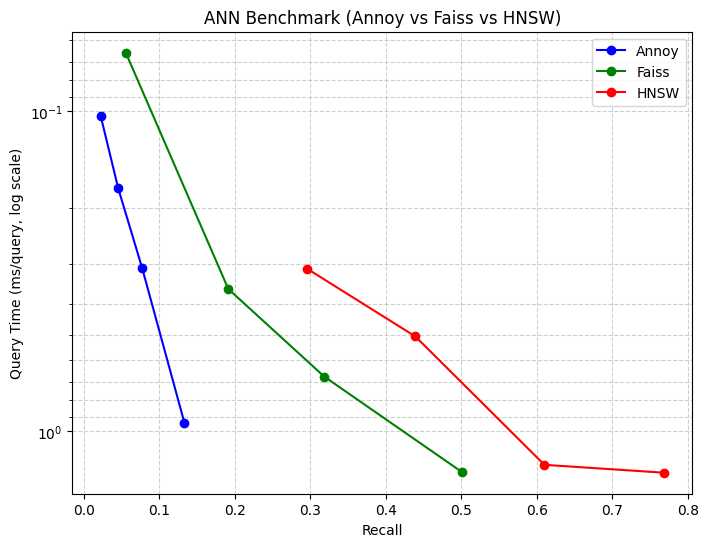

In [21]:
import numpy as np
import time
import faiss
from annoy import AnnoyIndex
import hnswlib
import matplotlib.pyplot as plt

# -------------------------------
# Random dataset
# -------------------------------
d = 128        # dimension
nb = 100000    # number of database vectors
nq = 1000      # number of queries

np.random.seed(42)
xb = np.random.random((nb, d)).astype('float32')
xq = np.random.random((nq, d)).astype('float32')

# -------------------------------
# Ground truth with FAISS brute force
# -------------------------------
index_flat = faiss.IndexFlatL2(d)
index_flat.add(xb)
k = 10
_, gt_idx = index_flat.search(xq, k)

# -------------------------------
# Recall function
# -------------------------------
def recall_at_k(I_pred, I_gt, k):
    correct = 0
    for i in range(len(I_pred)):
        correct += len(set(I_pred[i][:k]) & set(I_gt[i][:k]))
    return correct / (len(I_pred) * k)

# -------------------------------
# Annoy benchmark
# -------------------------------
def run_annoy(xb, xq, n_trees=10, search_k=1000, k=10):
    f = xb.shape[1]
    index = AnnoyIndex(f, 'euclidean')
    for i, v in enumerate(xb):
        index.add_item(i, v)
    index.build(n_trees)

    start = time.time()
    I = [index.get_nns_by_vector(v, k, search_k=search_k) for v in xq]
    elapsed = (time.time() - start) * 1000 / len(xq)  # ms/query
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# FAISS IVF benchmark
# -------------------------------
def run_faiss(xb, xq, nlist=100, nprobe=10, k=10):
    quantizer = faiss.IndexFlatL2(d)
    index = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_L2)
    index.train(xb)
    index.add(xb)

    index.nprobe = nprobe
    start = time.time()
    _, I = index.search(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# HNSW benchmark
# -------------------------------
def run_hnsw(xb, xq, ef=100, M=16, k=10):
    num_elements = xb.shape[0]
    p = hnswlib.Index(space='l2', dim=d)
    p.init_index(max_elements=num_elements, ef_construction=200, M=M)
    p.add_items(xb)
    p.set_ef(ef)

    start = time.time()
    I, _ = p.knn_query(xq, k)
    elapsed = (time.time() - start) * 1000 / len(xq)
    rec = recall_at_k(I, gt_idx, k)
    return rec, elapsed

# -------------------------------
# Run benchmark with several parameters
# -------------------------------
results = {"Annoy": [], "Faiss": [], "HNSW": []}

# Annoy
for sk in [200, 500, 1000, 2000]:
    rec, t = run_annoy(xb, xq, n_trees=10, search_k=sk)
    results["Annoy"].append((rec, t))

# FAISS
for npb in [1, 5, 10, 20]:
    rec, t = run_faiss(xb, xq, nlist=100, nprobe=npb)
    results["Faiss"].append((rec, t))

# HNSW
for ef in [50, 100, 200, 400]:
    rec, t = run_hnsw(xb, xq, ef=ef)
    results["HNSW"].append((rec, t))

# -------------------------------
# Visualize the trade-off
# -------------------------------
plt.figure(figsize=(8,6))
for label, color in zip(results.keys(), ["blue","green","red"]):
    recall, qtime = zip(*results[label])
    plt.plot(recall, qtime, marker="o", label=label, color=color)

plt.xlabel("Recall")
plt.ylabel("Query Time (ms/query, log scale)")
plt.yscale("log")
plt.gca().invert_yaxis()  # invert Y, the more to the right the lower
plt.title("ANN Benchmark (Annoy vs Faiss vs HNSW)")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.show()

Assignment 1

In [19]:
import time
import numpy as np
from annoy import AnnoyIndex
import faiss
import hnswlib

def exact_knn(data: np.ndarray, queries: np.ndarray, k: int = 10, metric: str = "l2"):
    if metric == "l2":
        # Squared Euclidean distance
        dists = ((queries[:, None, :] - data[None, :, :]) ** 2).sum(axis=2)
        return np.argsort(dists, axis=1)[:, :k]
    else:
        # Cosine similarity on normalized vectors
        d_norm = data / (np.linalg.norm(data, axis=1, keepdims=True) + 1e-12)
        q_norm = queries / (np.linalg.norm(queries, axis=1, keepdims=True) + 1e-12)
        sims = q_norm @ d_norm.T
        return np.argsort(-sims, axis=1)[:, :k]

def recall_at_k(pred: np.ndarray, truth: np.ndarray, k: int = 10) -> float:
    hits = 0
    for p, t in zip(pred, truth):
        hits += len(set(p[:k]).intersection(set(t[:k])))
    return hits / (len(truth) * k)

def run_benchmark(n_samples: int, dim: int, metric: str = "l2", k: int = 10, n_queries: int = 100):
    rng = np.random.default_rng(42)
    data = rng.random((n_samples, dim), dtype=np.float32)
    queries = rng.random((n_queries, dim), dtype=np.float32)
    truth = exact_knn(data, queries, k=k, metric=metric)

    results = {}

    # 1. ANNOY
    annoy_metric = "euclidean" if metric == "l2" else "angular"
    t0 = time.perf_counter()
    ann = AnnoyIndex(dim, annoy_metric)
    for i, vec in enumerate(data):
        ann.add_item(i, vec.tolist())
    ann.build(10)
    build_ms = (time.perf_counter() - t0) * 1000

    t0 = time.perf_counter()
    ann_preds = np.array([ann.get_nns_by_vector(q.tolist(), k) for q in queries])
    query_ms = ((time.perf_counter() - t0) * 1000) / n_queries
    results["ANNOY"] = (build_ms, query_ms, recall_at_k(ann_preds, truth, k))

    # 2. FAISS (Flat index for exact/baseline; switch to IndexHNSWFlat/IVF for large scale)
    t0 = time.perf_counter()
    if metric == "l2":
        index_f = faiss.IndexFlatL2(dim)
        index_f.add(data)
        q_in = queries
    else:
        index_f = faiss.IndexFlatIP(dim)
        d_norm = data / (np.linalg.norm(data, axis=1, keepdims=True) + 1e-12)
        q_in = queries / (np.linalg.norm(queries, axis=1, keepdims=True) + 1e-12)
        index_f.add(d_norm)
    build_ms = (time.perf_counter() - t0) * 1000

    t0 = time.perf_counter()
    _, faiss_preds = index_f.search(q_in, k)
    query_ms = ((time.perf_counter() - t0) * 1000) / n_queries
    results["FAISS"] = (build_ms, query_ms, recall_at_k(faiss_preds, truth, k))

    # 3. HNSW (hnswlib)
    hnsw_space = "l2" if metric == "l2" else "cosine"
    t0 = time.perf_counter()
    p = hnswlib.Index(space=hnsw_space, dim=dim)
    p.init_index(max_elements=n_samples, ef_construction=200, M=16)
    p.add_items(data, np.arange(n_samples))
    p.set_ef(50)
    build_ms = (time.perf_counter() - t0) * 1000

    t0 = time.perf_counter()
    hnsw_preds, _ = p.knn_query(queries, k=k)
    query_ms = ((time.perf_counter() - t0) * 1000) / n_queries
    results["HNSW"] = (build_ms, query_ms, recall_at_k(hnsw_preds, truth, k))

    return results

for n, d in [(1_000, 2), (1_000, 5), (1_000_000, 2), (1_000_000, 5)]:
    for m in ["l2", "cosine"]:
        res = run_benchmark(n, d, metric=m)
        print(f"N={n}, D={d}, Metric={m} -> {res}")

N=1000, D=2, Metric=l2 -> {'ANNOY': (38.16512100002001, 0.035350309999557794, 0.999), 'FAISS': (0.2660050000713454, 0.06381635999900936, 1.0), 'HNSW': (119.29774800000814, 0.023486300000286064, 1.0)}
N=1000, D=2, Metric=cosine -> {'ANNOY': (74.61732899992057, 0.0579925399995318, 0.999), 'FAISS': (0.4338279999274164, 0.04262285999971027, 1.0), 'HNSW': (114.73369200007255, 0.03947027999970487, 0.999)}
N=1000, D=5, Metric=l2 -> {'ANNOY': (36.500567000075534, 0.0561167499995463, 0.968), 'FAISS': (0.1749220000419882, 0.10253477999981442, 1.0), 'HNSW': (114.68499300008261, 0.027329789999157583, 1.0)}
N=1000, D=5, Metric=cosine -> {'ANNOY': (39.63931999999204, 0.05038958999989518, 0.976), 'FAISS': (0.46731700001600984, 0.00870382999892172, 1.0), 'HNSW': (122.46285499998066, 0.029660899999726098, 1.0)}
N=1000000, D=2, Metric=l2 -> {'ANNOY': (33021.886655, 0.07729334000032395, 0.99), 'FAISS': (6.001010000090901, 5.996833320000405, 1.0), 'HNSW': (157317.95433399998, 0.04831370000147217, 1.0)}
N=

In [24]:
import time
import numpy as np
import pandas as pd
import faiss
import hnswlib
from annoy import AnnoyIndex
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

from google.colab import files
uploaded = files.upload()

# ------------------------------------------------
# Load dataset
# ------------------------------------------------
df = pd.read_csv("spotify_audio_features.csv")

features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
]  #[cite: 2]

# Keep rows with valid numerical features so ANN libraries don't fail on NaNs
valid_mask = df[features].notna().all(axis=1)
df_clean = df.loc[valid_mask].reset_index(drop=True)

X = df_clean[features].astype(np.float32).values  #[cite: 2]

# Feature standardization
scaler = StandardScaler()  #[cite: 2]
X_scaled = scaler.fit_transform(X).astype(np.float32)  #[cite: 2]

n_samples, dim = X_scaled.shape
k = 10  # number of nearest neighbors[cite: 2]

# Pick a query song (e.g., index 0) or a batch of queries for timing
query_idx = 0
query_vec = X_scaled[query_idx : query_idx + 1]

def recall_at_k(pred_indices: np.ndarray, true_indices: np.ndarray, k: int = 10) -> float:
    hits = 0
    for p, t in zip(pred_indices, true_indices):
        hits += len(set(p[:k]).intersection(set(t[:k])))
    return hits / (len(true_indices) * k)

# ------------------------------------------------
# 1. Exact NN (scikit-learn NearestNeighbors)
# ------------------------------------------------
t0 = time.perf_counter()
exact_nn = NearestNeighbors(n_neighbors=k, metric="euclidean", algorithm="brute")
exact_nn.fit(X_scaled)
exact_build_ms = (time.perf_counter() - t0) * 1000

t0 = time.perf_counter()
exact_dists, exact_idx = exact_nn.kneighbors(query_vec)
exact_query_ms = (time.perf_counter() - t0) * 1000

# ------------------------------------------------
# 2. ANNOY
# ------------------------------------------------
n_trees = 10
search_k = -1  # default search_k = n_trees * k

t0 = time.perf_counter()
annoy_index = AnnoyIndex(dim, "euclidean")
for i, vec in enumerate(X_scaled):
    annoy_index.add_item(i, vec.tolist())
annoy_index.build(n_trees)
annoy_build_ms = (time.perf_counter() - t0) * 1000

t0 = time.perf_counter()
annoy_neighbors = annoy_index.get_nns_by_vector(query_vec[0].tolist(), k, search_k=search_k)
annoy_query_ms = (time.perf_counter() - t0) * 1000
annoy_idx = np.array([annoy_neighbors])

# ------------------------------------------------
# 3. FAISS (IndexFlatL2)
# ------------------------------------------------
t0 = time.perf_counter()
faiss_index = faiss.IndexFlatL2(dim)
faiss_index.add(X_scaled)
faiss_build_ms = (time.perf_counter() - t0) * 1000

t0 = time.perf_counter()
faiss_dists, faiss_idx = faiss_index.search(query_vec, k)
faiss_query_ms = (time.perf_counter() - t0) * 1000

# ------------------------------------------------
# 4. HNSW (hnswlib)
# ------------------------------------------------
t0 = time.perf_counter()
hnsw_index = hnswlib.Index(space="l2", dim=dim)
hnsw_index.init_index(max_elements=n_samples, ef_construction=200, M=16)
hnsw_index.add_items(X_scaled, np.arange(n_samples))
hnsw_index.set_ef(50)
hnsw_build_ms = (time.perf_counter() - t0) * 1000

t0 = time.perf_counter()
hnsw_idx, hnsw_dists = hnsw_index.knn_query(query_vec, k=k)
hnsw_query_ms = (time.perf_counter() - t0) * 1000

# ------------------------------------------------
# Compare Nearest Tracks
# ------------------------------------------------
track_col = "track_name" if "track_name" in df_clean.columns else df_clean.columns[0]
artist_col = "track_artist" if "track_artist" in df_clean.columns else None

def format_tracks(indices):
    names = []
    for idx in indices:
        title = df_clean.loc[idx, track_col]
        if artist_col:
            names.append(f"{title} — {df_clean.loc[idx, artist_col]}")
        else:
            names.append(str(title))
    return names

print(f"\nQuery Track (index {query_idx}): {format_tracks([query_idx])[0]}\n")
for method_name, idx_arr in [
    ("Exact NN", exact_idx[0]),
    ("ANNOY", annoy_idx[0]),
    ("FAISS", faiss_idx[0]),
    ("HNSW", hnsw_idx[0]),
]:
    print(f"=== {method_name} Top-{k} ===")
    for rank, item in enumerate(format_tracks(idx_arr), start=1):
        print(f"  {rank:2d}. {item}")
    print()

# ------------------------------------------------
# Summary Comparison Table
# ------------------------------------------------
summary_df = pd.DataFrame(
    [
        {
            "Algorithm": "Exact NN (sklearn)",
            "Build Time (ms)": round(exact_build_ms, 2),
            "Query Time (ms)": round(exact_query_ms, 4),
            "Recall@10": round(recall_at_k(exact_idx, exact_idx, k), 4),
        },
        {
            "Algorithm": "ANNOY",
            "Build Time (ms)": round(annoy_build_ms, 2),
            "Query Time (ms)": round(annoy_query_ms, 4),
            "Recall@10": round(recall_at_k(annoy_idx, exact_idx, k), 4),
        },
        {
            "Algorithm": "FAISS (IndexFlatL2)",
            "Build Time (ms)": round(faiss_build_ms, 2),
            "Query Time (ms)": round(faiss_query_ms, 4),
            "Recall@10": round(recall_at_k(faiss_idx, exact_idx, k), 4),
        },
        {
            "Algorithm": "HNSW",
            "Build Time (ms)": round(hnsw_build_ms, 2),
            "Query Time (ms)": round(hnsw_query_ms, 4),
            "Recall@10": round(recall_at_k(hnsw_idx, exact_idx, k), 4),
        },
    ]
)

print(summary_df.to_markdown(index=False))

Saving spotify_audio_features.csv to spotify_audio_features (1).csv

Query Track (index 0): 0.415

=== Exact NN Top-10 ===
   1. 0.415
   2. 0.486
   3. 0.43
   4. 0.412
   5. 0.351
   6. 0.505
   7. 0.373
   8. 0.484
   9. 0.394
  10. 0.449

=== ANNOY Top-10 ===
   1. 0.415
   2. 0.43
   3. 0.412
   4. 0.505
   5. 0.484
   6. 0.449
   7. 0.411
   8. 0.466
   9. 0.409
  10. 0.536

=== FAISS Top-10 ===
   1. 0.415
   2. 0.486
   3. 0.43
   4. 0.412
   5. 0.351
   6. 0.505
   7. 0.373
   8. 0.484
   9. 0.394
  10. 0.449

=== HNSW Top-10 ===
   1. 0.415
   2. 0.486
   3. 0.43
   4. 0.412
   5. 0.351
   6. 0.505
   7. 0.373
   8. 0.484
   9. 0.394
  10. 0.449

| Algorithm           |   Build Time (ms) |   Query Time (ms) |   Recall@10 |
|:--------------------|------------------:|------------------:|------------:|
| Exact NN (sklearn)  |             37.86 |          150.81   |         1   |
| ANNOY               |          20859.3  |            0.2775 |         0.6 |
| FAISS (IndexFlatL2) |